<a href="https://colab.research.google.com/github/sileysa/Semester_5/blob/main/JS10_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Import Library dan Seed

In [1]:
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# 2. Load Dataset MNIST

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train: (60000, 28, 28) (60000,)
Test : (10000, 28, 28) (10000,)
Distribusi kelas train: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


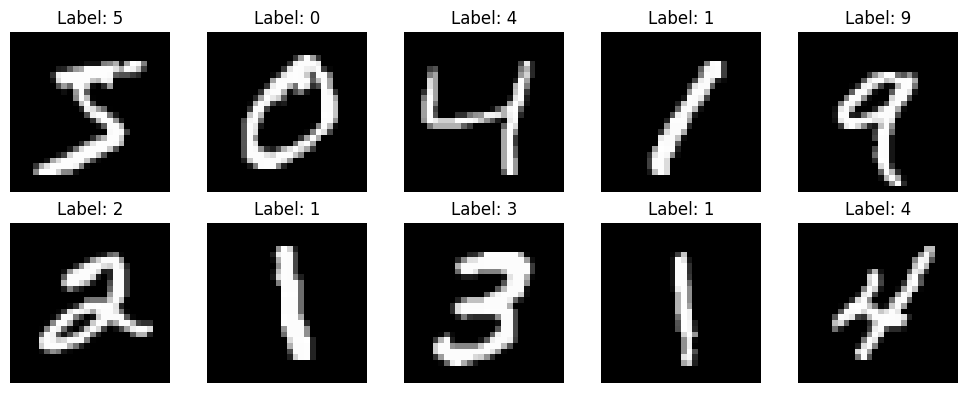

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)
print("Distribusi kelas train:", np.bincount(y_train))

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[i], cmap='gray')
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis('off')
plt.tight_layout()
plt.show()

# 3. Pra Pengolahan dan Fitur
Citra 28x28 diratakan (flatten) menjadi 784 fitur. Lalu dibuat beberapa versi fitur untuk dibandingkan:
- **raw**: piksel 0-255 tanpa normalisasi
- **minmax**: piksel dibagi 255 (rentang 0-1)
- **standard**: StandardScaler (rata-rata 0, simpangan baku 1)
- **pca**: standardisasi lalu PCA 100 komponen (pemilihan/reduksi fitur)

In [3]:
X_train_flat = X_train.reshape(-1, 784).astype('float32')
X_test_flat  = X_test.reshape(-1, 784).astype('float32')

features = {}

# raw
features['raw'] = (X_train_flat, X_test_flat)

# min-max
features['minmax'] = (X_train_flat / 255.0, X_test_flat / 255.0)

# standardisasi (fit hanya pada data latih)
sc = StandardScaler()
X_tr_std = sc.fit_transform(X_train_flat)
X_te_std = sc.transform(X_test_flat)
features['standard'] = (X_tr_std, X_te_std)

# PCA 100 komponen
pca = PCA(n_components=100, random_state=SEED)
X_tr_pca = pca.fit_transform(X_tr_std)
X_te_pca = pca.transform(X_te_std)
features['pca'] = (X_tr_pca, X_te_pca)
print("Variansi yang dipertahankan PCA:", round(pca.explained_variance_ratio_.sum(), 3))

for k, (a, b) in features.items():
    print(k, a.shape, b.shape)

Variansi yang dipertahankan PCA: 0.706
raw (60000, 784) (10000, 784)
minmax (60000, 784) (10000, 784)
standard (60000, 784) (10000, 784)
pca (60000, 100) (10000, 100)


# 4. Fungsi Membangun dan Melatih Model
Output layer: 10 node dengan `softmax` (10 kelas digit) dan loss `sparse_categorical_crossentropy`, karena label berupa bilangan bulat 0-9.
Data latih dibagi 90% training dan 10% validasi (`validation_split=0.1`). Data test hanya dipakai untuk evaluasi akhir.

In [4]:
def build_model(input_dim, hidden=(128, 64), activation='relu', dropout=0.0, optimizer='adam'):
    model = models.Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    for units in hidden:
        model.add(layers.Dense(units, activation=activation))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

results = []
store = {}   # menyimpan model, history, dan fitur test tiap eksperimen

def run_experiment(name, feat, hidden=(128, 64), activation='relu',
                   dropout=0.0, optimizer='adam', epochs=10):
    tf.keras.utils.set_random_seed(SEED)     # seed sama untuk tiap eksperimen
    Xtr, Xte = features[feat]
    model = build_model(Xtr.shape[1], hidden, activation, dropout, optimizer)
    t0 = time.time()
    hist = model.fit(Xtr, y_train, epochs=epochs, batch_size=128,
                     validation_split=0.1, verbose=0)
    dur = time.time() - t0
    test_loss, test_acc = model.evaluate(Xte, y_test, verbose=0)
    results.append({
        'Eksperimen': name, 'Fitur': feat, 'Hidden': str(hidden),
        'Aktivasi': activation, 'Dropout': dropout,
        'Train Acc': round(hist.history['accuracy'][-1], 4),
        'Val Acc': round(hist.history['val_accuracy'][-1], 4),
        'Test Acc': round(test_acc, 4),
        'Params': model.count_params(), 'Waktu (s)': round(dur, 1)
    })
    store[name] = {'model': model, 'history': hist, 'Xte': Xte}
    print(f"{name:35s} val={results[-1]['Val Acc']:.4f}  test={test_acc:.4f}")

# 5. Eksplorasi A - Metode Pra Pengolahan dan Fitur
Arsitektur tetap (128-64, ReLU), hanya fitur yang diubah.

In [5]:
run_experiment('A1 raw (0-255)',   'raw')
run_experiment('A2 minmax (/255)', 'minmax')
run_experiment('A3 standardisasi', 'standard')
run_experiment('A4 PCA 100 komp.', 'pca')

A1 raw (0-255)                      val=0.9582  test=0.9467
A2 minmax (/255)                    val=0.9732  test=0.9707
A3 standardisasi                    val=0.9713  test=0.9687
A4 PCA 100 komp.                    val=0.9752  test=0.9679


# 6. Eksplorasi B - Fungsi Aktivasi
Fitur min-max, arsitektur 128-64, hanya aktivasi yang diubah (A2 = ReLU sebagai pembanding).

In [6]:
run_experiment('B1 tanh',    'minmax', activation='tanh')
run_experiment('B2 sigmoid', 'minmax', activation='sigmoid')

B1 tanh                             val=0.9770  test=0.9707
B2 sigmoid                          val=0.9745  test=0.9698


# 7. Eksplorasi C - Arsitektur
Fitur min-max, aktivasi ReLU, jumlah layer/node dan dropout diubah.

In [7]:
run_experiment('C1 1 layer (64)',         'minmax', hidden=(64,))
run_experiment('C2 lebih lebar (256-128)', 'minmax', hidden=(256, 128))
run_experiment('C3 lebih dalam (256-128-64)', 'minmax', hidden=(256, 128, 64))
run_experiment('C4 256-128 + dropout 0.2', 'minmax', hidden=(256, 128), dropout=0.2)

C1 1 layer (64)                     val=0.9720  test=0.9707
C2 lebih lebar (256-128)            val=0.9772  test=0.9740
C3 lebih dalam (256-128-64)         val=0.9727  test=0.9706
C4 256-128 + dropout 0.2            val=0.9828  test=0.9802


# 8. Tabel Perbandingan Seluruh Eksperimen

In [8]:
df_res = pd.DataFrame(results)
df_res['Gap (Train-Val)'] = (df_res['Train Acc'] - df_res['Val Acc']).round(4)
df_res.sort_values('Val Acc', ascending=False)

,Eksperimen,Fitur,Hidden,Aktivasi,Dropout,Train Acc,Val Acc,Test Acc,Params,Waktu (s),Gap (Train-Val)
9,C4 256-128 + dropout 0.2,minmax,"(256, 128)",relu,0.2,0.9876,0.9828,0.9802,235146,60.1,0.0048
7,C2 lebih lebar (256-128),minmax,"(256, 128)",relu,0.0,0.9954,0.9772,0.9740,235146,45.9,0.0182
4,B1 tanh,minmax,"(128, 64)",tanh,0.0,0.9962,0.9770,0.9707,109386,38.1,0.0192
3,A4 PCA 100 komp.,pca,"(128, 64)",relu,0.0,0.9900,0.9752,0.9679,21834,29.9,0.0148
5,B2 sigmoid,minmax,"(128, 64)",sigmoid,0.0,0.9819,0.9745,0.9698,109386,50.3,0.0074
1,A2 minmax (/255),minmax,"(128, 64)",relu,0.0,0.9944,0.9732,0.9707,109386,30.0,0.0212
8,C3 lebih dalam (256-128-64),minmax,"(256, 128, 64)",relu,0.0,0.9948,0.9727,0.9706,242762,41.6,0.0221
6,C1 1 layer (64),minmax,"(64,)",relu,0.0,0.9835,0.9720,0.9707,50890,18.7,0.0115
2,A3 standardisasi,standard,"(128, 64)",relu,0.0,0.9931,0.9713,0.9687,109386,33.7,0.0218
0,A1 raw (0-255),raw,"(128, 64)",relu,0.0,0.9735,0.9582,0.9467,109386,39.8,0.0153


# 9. Pilih Model Terbaik
Model terbaik dipilih berdasarkan **akurasi validasi** (bukan akurasi test) supaya data test tetap murni untuk evaluasi akhir.

In [9]:
best_name = df_res.sort_values('Val Acc', ascending=False).iloc[0]['Eksperimen']
print("Model terbaik:", best_name)

best = store[best_name]
best_model, best_hist, best_Xte = best['model'], best['history'], best['Xte']
best_model.summary()

Model terbaik: C4 256-128 + dropout 0.2


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_27 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

# 10. Kurva Training Model Terbaik

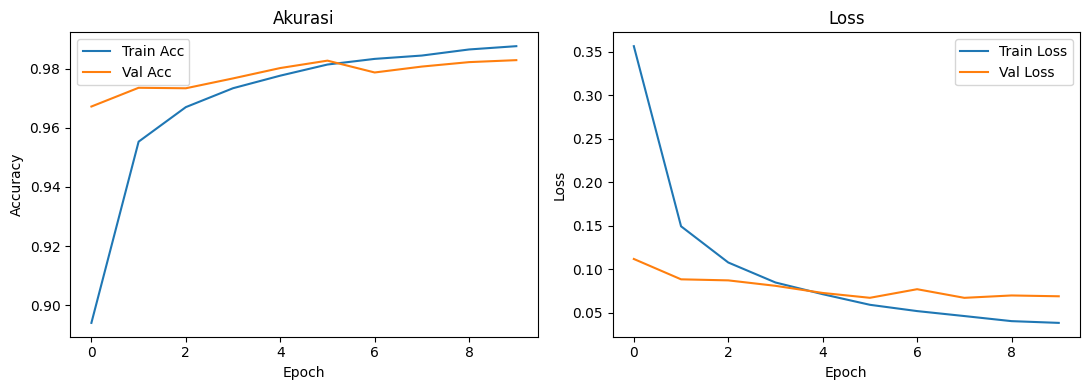

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(best_hist.history['accuracy'], label='Train Acc')
ax[0].plot(best_hist.history['val_accuracy'], label='Val Acc')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy'); ax[0].legend(); ax[0].set_title('Akurasi')
ax[1].plot(best_hist.history['loss'], label='Train Loss')
ax[1].plot(best_hist.history['val_loss'], label='Val Loss')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss'); ax[1].legend(); ax[1].set_title('Loss')
plt.tight_layout()
plt.show()

# 11. Evaluasi Akhir pada Data Test

Akurasi test: 0.9802
              precision    recall  f1-score   support

           0     0.9838    0.9898    0.9868       980
           1     0.9869    0.9921    0.9895      1135
           2     0.9722    0.9835    0.9778      1032
           3     0.9763    0.9802    0.9783      1010
           4     0.9731    0.9929    0.9829       982
           5     0.9897    0.9731    0.9813       892
           6     0.9853    0.9823    0.9838       958
           7     0.9727    0.9718    0.9723      1028
           8     0.9706    0.9836    0.9771       974
           9     0.9928    0.9514    0.9717      1009

    accuracy                         0.9802     10000
   macro avg     0.9803    0.9801    0.9801     10000
weighted avg     0.9803    0.9802    0.9802     10000



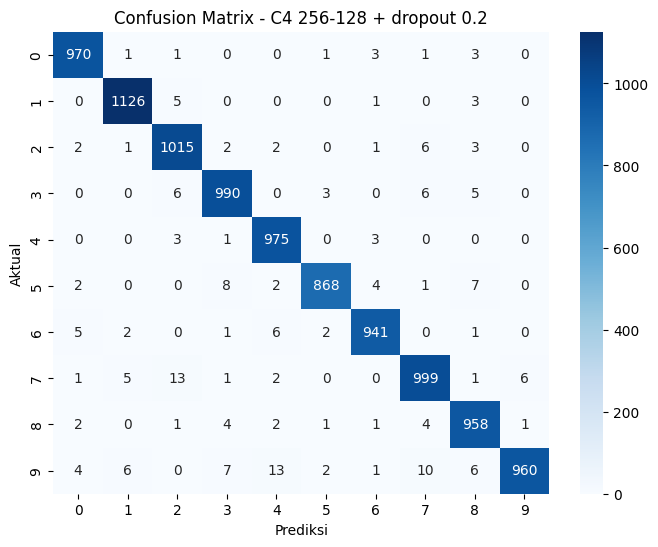

In [11]:
y_pred = np.argmax(best_model.predict(best_Xte, verbose=0), axis=1)

print("Akurasi test:", (y_pred == y_test).mean())
print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.title('Confusion Matrix - ' + best_name)
plt.show()

# 12. Contoh Prediksi yang Salah

Jumlah salah prediksi: 198


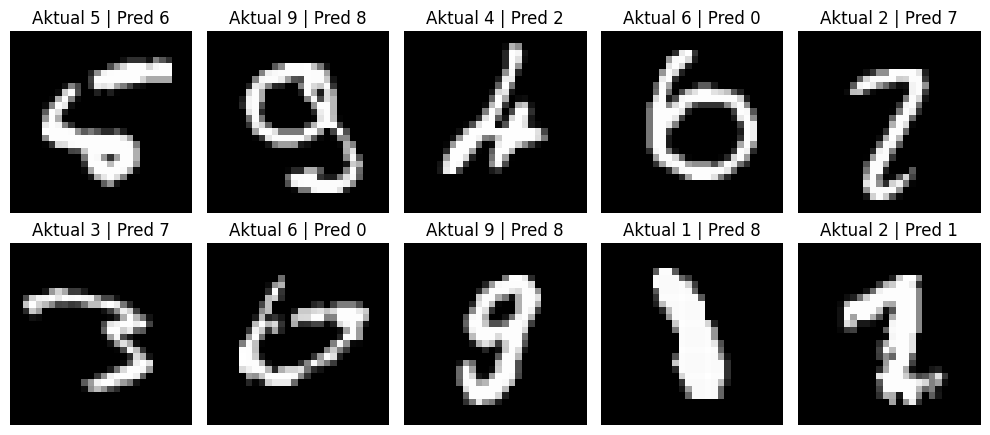

In [12]:
wrong = np.where(y_pred != y_test)[0]
print("Jumlah salah prediksi:", len(wrong))

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, idx in zip(axes.ravel(), wrong[:10]):
    ax.imshow(X_test[idx], cmap='gray')
    ax.set_title(f"Aktual {y_test[idx]} | Pred {y_pred[idx]}")
    ax.axis('off')
plt.tight_layout()
plt.show()

# 13. Simpan Model

In [13]:
best_model.save('mnist_ann_best.keras')